In [1]:
import geomstats.backend as gs
import matplotlib.pyplot as plt
import numpy as np
from geomstats.geometry.poincare_ball import PoincareBall

INFO: Substituting symbol R from STIXGeneral
INFO: Substituting symbol R from STIXGeneral


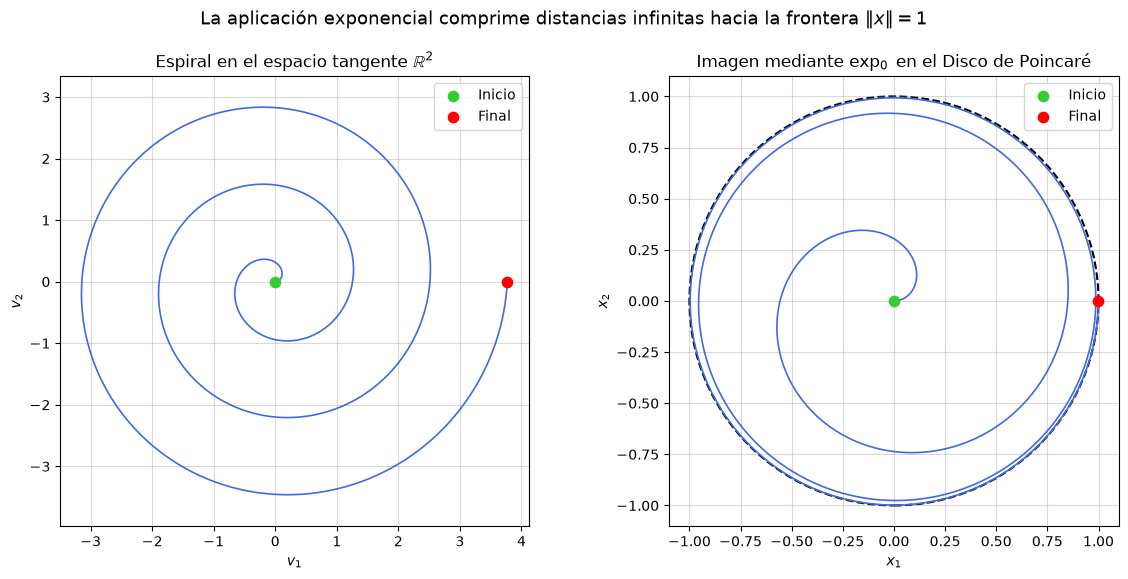

In [ ]:
# Crear una espiral creciente con norma controlada en R²

theta = np.linspace(0, 6 * np.pi, 2000)  # 3 vueltas completas

# Ajustamos el crecimiento del radio para que en el espacio tangente
radius = 0.2 * theta

spiral_tangent = np.column_stack(
    (
        radius * np.cos(theta),
        radius * np.sin(theta),
    )
)

#  Mapear la espiral al disco de Poincaré mediante exp en el origen
disk = PoincareBall(dim=2)

spiral_disk = disk.metric.exp(
    tangent_vec=gs.array(spiral_tangent),
    base_point=gs.zeros(2),
)
spiral_disk = np.asarray(spiral_disk)

# Plots
fig, (ax1, ax2) = plt.subplots(
    1,
    2,
    figsize=(12, 6),
    facecolor="white",
)

curve_color = "royalblue"

for ax in (ax1, ax2):
    ax.set_facecolor("white")
    ax.tick_params(colors="black")
    ax.xaxis.label.set_color("black")
    ax.yaxis.label.set_color("black")
    ax.title.set_color("black")
    ax.grid(color="gray", alpha=0.3)

# Gráfico 1: Espacio tangente R²
ax1.plot(
    spiral_tangent[:, 0],
    spiral_tangent[:, 1],
    color=curve_color,
    linewidth=1.2,
)
ax1.scatter(
    *spiral_tangent[0],
    color="limegreen",
    s=55,
    label="Inicio",
    zorder=3,
)
ax1.scatter(
    *spiral_tangent[-1],
    color="red",
    s=55,
    label="Final",
    zorder=3,
)

ax1.set_title("Espiral en el espacio tangente $\\mathbb{R}^2$")
ax1.set_xlabel("$v_1$")
ax1.set_ylabel("$v_2$")
ax1.axis("equal")
ax1.legend()


# Gráfico 2: Disco de Poincaré
ax2.add_patch(
    plt.Circle(
        (0, 0),
        1.0,
        fill=False,
        color="black",
        linestyle="--",
        linewidth=1.5,
    )
)

ax2.plot(
    spiral_disk[:, 0],
    spiral_disk[:, 1],
    color=curve_color,
    linewidth=1.2,
)
ax2.scatter(
    *spiral_disk[0],
    color="limegreen",
    s=55,
    label="Inicio",
    zorder=3,
)
ax2.scatter(
    *spiral_disk[-1],
    color="red",
    s=55,
    label="Final",
    zorder=3,
)

ax2.set_title("Imagen mediante $\\exp_0$ en el Disco de Poincaré")
ax2.set_xlabel("$x_1$")
ax2.set_ylabel("$x_2$")
ax2.set_xlim(-1.1, 1.1)
ax2.set_ylim(-1.1, 1.1)
ax2.set_aspect("equal")
ax2.legend()

fig.suptitle(
    "La aplicación exponencial comprime distancias infinitas hacia la frontera $\|x\| = 1$",
    fontsize=13,
    color="black",
)
fig.subplots_adjust(
    left=0.08,
    right=0.97,
    bottom=0.12,
    top=0.87,
    wspace=0.28,
)

plt.show()